# Context-dependent remapping

Reproduces Fig. 3 (Sec. 2.5): between-context similarity decaying with context separation,
and the rate maps at $s = 0$ and $s = 5$ showing that the grid structure survives while the
fields of individual units shift.

A scalar context enters exactly as the spatial coordinates do,
$p(x, y, s) = e^{xG_x + yG_y + sG_s}p_0$. The spatial generators are **metric-preserving**
(roots of unity, so grids) and the context generator is **similarity-preserving** (Gaussian
spectrum, so smooth decorrelation). There is no metric to preserve on a non-spatial variable,
only similarity.

**Construction (App. I).** The population consists of `N_SETS` hexagonal sets on one ring,
each rotated by its own orientation offset, so that no two subspaces share a wavevector. Every
set satisfies the balance condition of Sec. 2.4 on its own, so the spatial code stays
metric-preserving. The context eigenvalues are one seeded Gaussian draw per subspace. The
mixing matrix $R$ mixes within a set only (`block_diagonal_orthogonal`), so each unit is a grid
cell of one set.

**Why distinct wavevectors (App. I.1).** A context shift adds the phase $\lambda_{i,s}s$ to
the plane wave of the $i$-th subspace, the same for every unit. The spatial cross-correlogram
of two units is therefore unchanged by the shift when subspaces that share a wavevector also
share a context eigenvalue. With distinct wavevectors this holds automatically, so the pairwise
phase relations within a set are rigid under remapping while the fields of single units shift
and deform; the last section checks this on a periodic box. Sets whose orientations differ by
a few degrees cannot be told apart within the arena, so the invariance holds within a set and
not between neighboring sets. `03_context_dependent_remapping` is the construction of the
submitted version, which tiles the same three wavevectors with a context eigenvalue per copy.
It has the same similarity curve but not this property.

**Between-context similarity does not depend on position.** Because $G_s$ commutes with
$G_x$ and $G_y$ and all three are skew-symmetric, the spatial part cancels exactly,
$p(x,y,s_1)^\top p(x,y,s_2) = p_0^\top e^{\Delta s\,G_s}p_0 = C(\Delta s)$, which is Eq. 5.
The vertical scatter in the similarity panel is therefore **not** real spread across the
arena but ratemap binning error; a later cell shows the unbinned quantity is constant across
position to float32 precision.

**Parameters.** $M = 3$, $N = 300$ and $s: 0 \to 5$ are Fig. 3; the $[0, 5]$ context range
and the $20 \times 20$ spatial domain are Appendix A. The context spectrum is a seeded draw,
as in `03`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

import expmap
from expmap.analysis import batch_inference, compute_ratemaps, periodic_cross_correlograms
from expmap.generators import (
    block_diag_skew,
    build_generators_with_context,
    gaussian_eigenvalues,
    roots_of_unity_eigenvalues,
)
from expmap.linalg import block_diagonal_orthogonal, starting_state
from expmap.model import RemappingModel
from expmap.plotting import ratemap_collage
from expmap.simulation import generate_uniform_positions

# Figure parameters. M = 3 and the s = 0 -> 5 shift are Fig. 3; the 20 x 20 spatial
# domain and the [0, 5] context range are Appendix A. SEED fixes the context spectrum,
# the mixing matrix R and the position sampling.
M = 3
N_SETS = 50  # N = 2 * M * N_SETS = 300
CONTEXT_SCALE = np.sqrt(2)
ARENA_SIZE = 10
BINS = 32
BATCH_SIZE, BATCHES = 50, 500
CONTEXT_VALS = np.linspace(0, 5, 20)
SEED = 0

# Fig. 3 panels are drawn at their printed size (they are assembled in Inkscape), so nothing
# is scaled in LaTeX: the similarity panel and two 4 x 4 collages side by side across the
# 5.5 in text width.
SIMILARITY_PANEL = (1.9, 1.2)  # inches
COLLAGE_SIZE = 1.15  # inches, each 4 x 4 collage
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "stix",
        "svg.fonttype": "none",
        "font.size": 8,
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
    }
)

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

In [2]:
N = 2 * M * N_SETS

# Spatial: hexagonal sets on the unit ring, each rotated by its own offset, so
# that no two subspaces share a wavevector. Subspaces are ordered set by set.
base = roots_of_unity_eigenvalues(M)
offsets = np.arange(N_SETS) * np.pi / (M * N_SETS)
phi = (offsets[:, None] + base[None, :]).ravel()
sigma_x = block_diag_skew(np.cos(phi))
sigma_y = block_diag_skew(np.sin(phi))

# Context: the Gaussian spectrum of notebook 03 (same seed), one eigenvalue per subspace.
ev_s = gaussian_eigenvalues(N, scale=CONTEXT_SCALE, seed=SEED)
sigma_s = block_diag_skew(ev_s)

# R mixes within a set only, so each unit belongs to one set.
R = block_diagonal_orthogonal(N_SETS, 2 * M, seed=SEED)
p0 = starting_state(R)
Gx, Gy, Gs = build_generators_with_context(sigma_x, sigma_y, sigma_s, R)

model = RemappingModel(Gx, Gy, Gs)

for name, G in [("Gx", Gx), ("Gy", Gy), ("Gs", Gs)]:
    assert torch.allclose(G, -G.T, atol=1e-6), f"{name} must be skew-symmetric"
assert torch.allclose(Gx @ Gy, Gy @ Gx, atol=1e-5), "Gx must commute with Gy"
assert torch.allclose(Gx @ Gs, Gs @ Gx, atol=1e-5), "Gs must commute with Gx"
assert torch.allclose(Gy @ Gs, Gs @ Gy, atol=1e-5), "Gs must commute with Gy"

# The rigidity condition: no two subspaces share a wavevector.
assert len(np.unique(np.round(phi, 6))) == M * N_SETS

print(f"Number of units: {N}")

Number of units: 300


In [3]:
r_batch = generate_uniform_positions(BATCHES, BATCH_SIZE, ARENA_SIZE, seed=SEED)
r = np.concatenate(r_batch)

# The reference context. This does not depend on the comparison context, so it is
# computed once rather than inside the sweep below.
p_reference = batch_inference(model, r_batch, p0, context=0.0)
ratemaps_c1 = compute_ratemaps(r[:, 0], r[:, 1], p_reference, bins=BINS)

print(f"||p|| = {np.linalg.norm(p_reference, axis=1).mean():.6f}")

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 2/500 [00:00<00:27, 17.92it/s]

  1%|          | 4/500 [00:00<00:26, 18.73it/s]

  1%|          | 6/500 [00:00<00:26, 18.57it/s]

  2%|▏         | 8/500 [00:00<00:26, 18.44it/s]

  2%|▏         | 10/500 [00:00<00:27, 18.06it/s]

... (239 outputs left out)

 99%|█████████▉| 497/500 [00:27<00:00, 18.77it/s]

100%|█████████▉| 499/500 [00:27<00:00, 18.44it/s]

100%|██████████| 500/500 [00:27<00:00, 18.35it/s]

||p|| = 1.000000


In [4]:
# Sweep the context displacement and record the per-bin between-context similarity.
similarity_by_bin = []

for context in CONTEXT_VALS:
    p_shifted = batch_inference(model, r_batch, p0, context=float(context), progress=False)
    ratemaps_shifted = compute_ratemaps(r[:, 0], r[:, 1], p_shifted, bins=BINS)
    similarity_by_bin.append(np.nansum(ratemaps_c1 * ratemaps_shifted, axis=0))

similarity_by_bin = np.array(similarity_by_bin)
print(f"similarity_by_bin: {similarity_by_bin.shape}  (context values, bins_x, bins_y)")

similarity_by_bin: (20, 32, 32)  (context values, bins_x, bins_y)


max |binned mean - Eq. 5|     = 0.0308
rms |Eq. 5 - Gaussian target| = 0.0454
  finite-N noise floor 1/sqrt(N/2) = 0.0816


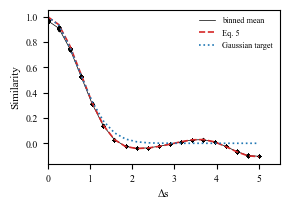

In [5]:
# Verification, not the paper panel (that is the next cell): the binned similarity against
# Eq. 5, C(ds) = sum_i alpha_0,i^2 cos(ds * lambda_i,s), with uniform coefficients 1/N.
# Because the context spectrum is Gaussian this is approximately exp(-scale^2 ds^2 / 2)
# -- the same factor of two as the spatial case in notebook 02.
ravelled = similarity_by_bin.reshape(len(CONTEXT_VALS), -1)
eq5 = np.array([np.sum((2 / N) * np.cos(ds * ev_s)) for ds in CONTEXT_VALS])
gaussian = np.exp(-(CONTEXT_SCALE**2) * CONTEXT_VALS**2 / 2)

plt.figure(figsize=(3, 2))
for i, ds in enumerate(CONTEXT_VALS):
    plt.scatter(ds * np.ones(ravelled.shape[-1]), ravelled[i], color="k", alpha=0.1, s=2)
plt.plot(CONTEXT_VALS, np.nanmean(ravelled, axis=-1), "k", linewidth=0.5, label="binned mean")
plt.plot(CONTEXT_VALS, eq5, "C3--", linewidth=1.2, label="Eq. 5")
plt.plot(CONTEXT_VALS, gaussian, "C0:", linewidth=1.2, label="Gaussian target")
plt.xlabel("Δs")
plt.ylabel("Similarity")
plt.xlim([0, 5.5])
plt.legend(fontsize=6, frameon=False)
plt.savefig(
    FIGURE_DIR / "Remapping_distinct_similarity_verification.svg", dpi=300, transparent=True, bbox_inches="tight"
)
plt.savefig(
    FIGURE_DIR / "Remapping_distinct_similarity_verification.png", dpi=300, transparent=True, bbox_inches="tight"
)

print(f"max |binned mean - Eq. 5|     = {np.nanmax(np.abs(np.nanmean(ravelled, axis=-1) - eq5)):.4f}")
print(f"rms |Eq. 5 - Gaussian target| = {np.sqrt(np.mean((eq5 - gaussian) ** 2)):.4f}")
print(f"  finite-N noise floor 1/sqrt(N/2) = {1 / np.sqrt(N // 2):.4f}")

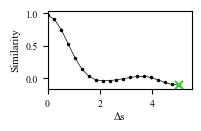

In [6]:
# Fig. 3, left: the paper panel. Per-bin between-context similarity (grey, binning scatter),
# its mean over bins with a marker at each context separation, and a cross at the shift
# s = 0 -> 5 whose ratemaps the right-hand panels show.
SHOWN_SHIFT = 5.0
mean_similarity = np.nanmean(ravelled, axis=-1)

plt.figure(figsize=SIMILARITY_PANEL, layout="constrained")
for i, ds in enumerate(CONTEXT_VALS):
    plt.scatter(ds * np.ones(ravelled.shape[-1]), ravelled[i], color="0.6", alpha=0.1, s=1, linewidths=0)
plt.plot(CONTEXT_VALS, mean_similarity, "k.-", linewidth=0.5, markersize=3)
shown = np.argmin(np.abs(CONTEXT_VALS - SHOWN_SHIFT))
plt.plot(SHOWN_SHIFT, mean_similarity[shown], "x", color="limegreen", markersize=6, markeredgewidth=1.5)
plt.xlabel("Δs", labelpad=2)
plt.ylabel("Similarity")
plt.xlim([0, 5.5])
plt.xticks([0, 2, 4])
plt.savefig(
    FIGURE_DIR / "Remapping_distinct_similarity.svg", dpi=300, transparent=True, bbox_inches="tight", pad_inches=0.02
)
plt.savefig(
    FIGURE_DIR / "Remapping_distinct_similarity.png", dpi=300, transparent=True, bbox_inches="tight", pad_inches=0.02
)

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 2/500 [00:00<00:24, 19.99it/s]

  1%|          | 4/500 [00:00<00:24, 19.99it/s]

  1%|          | 6/500 [00:00<00:24, 19.95it/s]

  2%|▏         | 9/500 [00:00<00:24, 20.07it/s]

  2%|▏         | 12/500 [00:00<00:24, 20.06it/s]

... (239 outputs left out)

 99%|█████████▉| 496/500 [00:29<00:00, 17.30it/s]

100%|█████████▉| 498/500 [00:29<00:00, 17.15it/s]

100%|██████████| 500/500 [00:29<00:00, 17.03it/s]

100%|██████████| 500/500 [00:29<00:00, 17.04it/s]

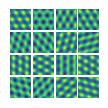

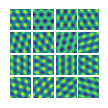

In [7]:
# Fig. 3, right: the same units at s = 0 and s = 5, four units from each of four sets (one set
# per row). The lattice of every unit is intact in both contexts; its fields shift and
# may deform. Both collages share one colour scale.
SHOWN_SETS = [0, 12, 25, 37]
shown_units = np.concatenate([2 * M * m + np.arange(4) for m in SHOWN_SETS])

p_c2 = batch_inference(model, r_batch, p0, context=SHOWN_SHIFT)
ratemaps_c2 = compute_ratemaps(r[:, 0], r[:, 1], p_c2, bins=BINS)

vmin = min(np.nanmin(ratemaps_c1[shown_units]), np.nanmin(ratemaps_c2[shown_units]))
vmax = max(np.nanmax(ratemaps_c1[shown_units]), np.nanmax(ratemaps_c2[shown_units]))
for ratemaps, name in [
    (ratemaps_c1, "Remapping_distinct_ratemaps_s0"),
    (ratemaps_c2, "Remapping_distinct_ratemaps_s5"),
]:
    fig, _ = ratemap_collage(
        ratemaps[shown_units], rows=4, cols=4, figsize=(COLLAGE_SIZE, COLLAGE_SIZE), vmin=vmin, vmax=vmax
    )
    fig.savefig(FIGURE_DIR / f"{name}.svg", dpi=300, transparent=True, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=300, transparent=True, bbox_inches="tight", pad_inches=0.02)

max spread across 4 positions = 9.54e-07  (float32 noise; 0 in exact arithmetic)
max |unbinned - Eq. 5|        = 3.83e-07


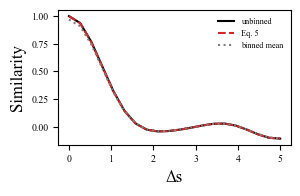

In [8]:
# The scatter above is binning error, not spatial structure. Evaluated at points rather
# than through ratemaps, the between-context similarity is the same everywhere, because
# the commuting skew-symmetric spatial generators cancel exactly.
probes = torch.tensor([[0.0, 0.0], [3.1, -2.4], [7.7, 5.2], [-9.0, 1.0]], dtype=torch.float32)

spreads, exact = [], []
for ds in CONTEXT_VALS:
    with torch.no_grad():
        a = model(probes, p0, context=0.0)
        b = model(probes, p0, context=float(ds))
    values = (a * b).sum(dim=1).numpy()
    spreads.append(values.max() - values.min())
    exact.append(values.mean())

print(f"max spread across 4 positions = {max(spreads):.2e}  (float32 noise; 0 in exact arithmetic)")
print(f"max |unbinned - Eq. 5|        = {np.max(np.abs(np.array(exact) - eq5)):.2e}")

plt.figure(figsize=(3, 2))
plt.plot(CONTEXT_VALS, exact, "k", label="unbinned")
plt.plot(CONTEXT_VALS, eq5, "C3--", label="Eq. 5")
plt.plot(CONTEXT_VALS, np.nanmean(ravelled, axis=-1), "C7:", label="binned mean")
plt.xlabel("Δs", fontsize=12)
plt.ylabel("Similarity", fontsize=12)
plt.legend(fontsize=6, frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Remapping_similarity_vs_eq5.svg", dpi=300, transparent=True)

## Pairwise phase relations under the context shift

The cross-correlogram of two units $n$ and $m$ of a set is

$$
\chi_{nm}(\boldsymbol{\Delta}) = \tfrac{1}{2}\sum_i a_{n,i}\,a_{m,i}
  \cos(\mathbf{k}_i\cdot\boldsymbol{\Delta} + \psi_{m,i} - \psi_{n,i}),
$$

with no dependence on $s$, when every wavevector belongs to a single subspace. The check
below evaluates each set on one period of its own lattice, where the periodic
cross-correlogram (`periodic_cross_correlograms`) is exact, and compares $s = 0$ with $s = 5$. The same comparison for the
construction of notebook `03` (identical copies, a context eigenvalue per copy, dense $R$)
is shown for contrast.

In [9]:
BOX_BINS = 32


def periodic_box(offset):
    # One period of the hexagonal lattice with unit wavenumber and wave directions
    # offset + (0, 60, 120) degrees. Specific to M = 3.
    x = np.linspace(0, 4 * np.pi, BOX_BINS, endpoint=False)
    y = np.linspace(0, 4 * np.pi / np.sqrt(3), BOX_BINS, endpoint=False)
    X, Y = np.meshgrid(x, y, indexing="ij")
    c, s = np.cos(offset), np.sin(offset)
    positions = np.stack([c * X - s * Y, s * X + c * Y], axis=-1).reshape(-1, 2)
    return torch.tensor(positions, dtype=torch.float32)


def correlogram_change(model, p0, positions, units):
    # Change in the normalized cross-correlograms of all pairs of `units` between s = 0 and
    # SHOWN_SHIFT, over all lags.
    correlograms = []
    for context in (0.0, SHOWN_SHIFT):
        p = batch_inference(model, positions.split(64), p0, context=context, progress=False)[:, units]
        correlograms.append(periodic_cross_correlograms(p.T.reshape(len(units), BOX_BINS, BOX_BINS)))
    return np.abs(correlograms[0] - correlograms[1])


changes = []
for m in SHOWN_SETS:
    units = 2 * M * m + np.arange(2 * M)
    changes.append(correlogram_change(model, p0, periodic_box(offsets[m]), units))
changes = np.array(changes)
print(f"distinct wavevectors, sets {SHOWN_SETS}:")
print(f"  change in pairwise cross-correlograms: max {changes.max():.1e}, median {np.median(changes):.1e}")

# Notebook 03: every unit mixes all copies, so any 30 units serve as the comparison.
tiled, p0_tiled = expmap.remapping_model(M=M, n_copies=N_SETS, context_scale=CONTEXT_SCALE, seed=SEED)
change_tiled = correlogram_change(tiled, p0_tiled, periodic_box(0.0), np.arange(30))
print("identical copies with a context eigenvalue per copy (notebook 03), 30 units:")
print(f"  change in pairwise cross-correlograms: max {change_tiled.max():.1e}, median {np.median(change_tiled):.1e}")

distinct wavevectors, sets [0, 12, 25, 37]:
  change in pairwise cross-correlograms: max 4.9e-07, median 7.5e-08


identical copies with a context eigenvalue per copy (notebook 03), 30 units:
  change in pairwise cross-correlograms: max 1.8e+00, median 4.0e-01
